# Full pipeline for simulation of neutrino interacting events from propgation through a 3D Earth (ModularEarth)

(c) Isabel Goos, Yael Deniz, Estelle Salomé, Mahé Lucas, Baptiste Lamy, Nobuaki Fuji

11/10/2026



## flexOPT interface
Flexopt offers all components for forward modeling of neutrino interacting events
Including cross section and Osicillation probability calculation
Several neutrino Neutrino Flux models, including Honda (Default), Daemon, and Cheng
Customizable 3D Earth Path generation (ModularEarth) 

In [1]:
# Locate flexOPT securely without relying on @__DIR__ (unreliable in IJulia).
# If this notebook is outside the repository, set ENV["FLEXOPT_ROOT"] first.
import Pkg

ENV["FLEXOPT_ROOT"] = "~/flexOPT"


function find_flexopt_root(start_dir=homedir())
    candidates = String[]
    if haskey(ENV, "FLEXOPT_ROOT")
        push!(candidates, abspath(expanduser(ENV["FLEXOPT_ROOT"])))
    end
    directory = abspath(start_dir)
    while true
        push!(candidates, directory)
        parent = dirname(directory)
        parent == directory && break
        directory = parent
    end
    for candidate in unique(candidates)
        project_file = joinpath(candidate, "Project.toml")
        source_dir = joinpath(candidate, "src")
        if isfile(project_file) && isfile(joinpath(source_dir, "commonBatchs.jl"))
            return candidate
        end
    end
    error("Cannot locate flexOPT. Start Jupyter inside the repository or set ENV[\"FLEXOPT_ROOT\"] to its absolute path.")
end

flexopt_root = find_flexopt_root()
Pkg.activate(flexopt_root)
@show VERSION Threads.nthreads() Base.active_project()


  Activating 

VERSION = v"1.12.6"

project at `~/flexOPT`



Threads.nthreads() = 1
Base.active_project() = "/home/ydenizhernandez/flexOPT/Project.toml"


"/home/ydenizhernandez/flexOPT/Project.toml"

In [2]:
println("\nActive project: ", Base.active_project())

Pkg.status()

for pkg in ["Plots", "IJulia", "PythonCall"]
    path = Base.find_package(pkg)
    println(pkg, ": ", path === nothing ? "NOT FOUND" : path)
end


Active project: /home/ydenizhernandez/flexOPT/Project.toml
Status `~/flexOPT/Project.toml`
  [39de3d68] AxisArrays v0.4.8
  [26cce99e] BasicInterpolators v0.7.1
  [6e4b80f9] BenchmarkTools v1.8.0
⌃ [336ed68f] CSV v0.10.16
⌃ [13f3f980] CairoMakie v0.13.10
⌃ [944b1d66] CodecZlib v0.7.8
⌃ [35d6a980] ColorSchemes v3.31.0
⌃ [5ae59095] Colors v0.13.1
  [efc8151c] DIVAnd v2.7.14
⌃ [717857b8] DSP v0.8.4
⌃ [a93c6f00] DataFrames v1.8.2
⌃ [82cc6244] DataInterpolations v8.10.0
  [8bb1440f] DelimitedFiles v1.9.1
⌅ [5b8099bc] DomainSets v0.7.18
  [634d3b9d] DrWatson v2.19.1
⌃ [7da242da] Enzyme v0.13.140
⌃ [5789e2e9] FileIO v1.19.0
  [48062228] FilePathsBase v0.9.24
⌃ [e9467ef8] GLMakie v0.11.11
⌃ [5752ebe1] GMT v1.40.0
⌅ [0c68f7d7] GPUArrays v11.5.3
  [0ef565a4] Geodesy v1.2.0
⌃ [86223c79] Graphs v1.13.1
  [7073ff75] IJulia v1.34.4
  [615f187c] IfElse v0.1.1
  [916415d5] Images v0.26.2
⌅ [a98d9a8b] Interpolations v0.15.1
⌃ [033835bb] JLD2 v0.6.4
⌃ [682c06a0] JSON v1.6.1
  [8ac3fa9e] LRUCache v1.6.2

In [3]:




include(joinpath(flexopt_root, "src", "neutrinoOscillation.jl")) # Working module directly from flexOPT
using .neutrinoOscillation
using .neutrinoOscillation: Path

# using Statistics, LaTeXStrings

using Statistics, CairoMakie, LaTeXStrings



include(joinpath(flexopt_root, "src", "neutrinoCrossSections.jl"))
using .Neutrino_Cross_Sections

include(joinpath(flexopt_root, "src", "neutrinoDetectorEffects", "perfectDetector.jl"))

include(joinpath(
    homedir(),
    "Joint-Inversion",
    "ForwardModel",
    "1-NeutrinoFlux",
    "scripts",
    "config.jl"
))

include(joinpath(
    homedir(),
    "Joint-Inversion",
    "ForwardModel",
    "1-NeutrinoFlux",
    "scripts",
    "generate_neutrino_flux.jl"
)) # Current module directly from Isabel-Goos/Joint-Inversion
# using .neutrinoFlux  # Add module to generate_neutrino_flux.jl?







_get_daemonflux_instance


# Pyhton Interface

In [4]:
# To implement ModularEarth, we need to implement the Python CERN ROOT interpreter compatible with Julia Kernels.


ENV["JULIA_PYTHONCALL_EXE"] = "/usr/bin/python3.12" #Where should the user look for this?

# Load packages
using Plots
using PythonCall

# Environment information
@show VERSION
@show Threads.nthreads()
@show Base.active_project()
@show Pkg.status()


ENV["JULIA_CONDAPKG_BACKEND"] = "Null"

pybuiltins = pyimport("builtins")  # Access Python's built-in functions (e.g., str(), type()) to handle Python objects returned by cppyy.
pyimport("sys").executable



VERSION = v"1.12.6"
Threads.nthreads() = 1
Base.active_project() = "/home/ydenizhernandez/flexOPT/Project.toml"
Status `~/flexOPT/Project.toml`
  [39de3d68] AxisArrays v0.4.8
  [26cce99e] BasicInterpolators v0.7.1
  [6e4b80f9] BenchmarkTools v1.8.0
⌃ [336ed68f] CSV v0.10.16
⌃ [13f3f980] CairoMakie v0.13.10
⌃ [944b1d66] CodecZlib v0.7.8
⌃ [35d6a980] ColorSchemes v3.31.0
⌃ [5ae59095] Colors v0.13.1
  [efc8151c] DIVAnd v2.7.14
⌃ [717857b8] DSP v0.8.4
⌃ [a93c6f00] DataFrames v1.8.2
⌃ [82cc6244] DataInterpolations v8.10.0
  [8bb1440f] DelimitedFiles v1.9.1
⌅ [5b8099bc] DomainSets v0.7.18
  [634d3b9d] DrWatson v2.19.1
⌃ [7da242da] Enzyme v0.13.140
⌃ [5789e2e9] FileIO v1.19.0
  [48062228] FilePathsBase v0.9.24
⌃ [e9467ef8] GLMakie v0.11.11
⌃ [5752ebe1] GMT v1.40.0
⌅ [0c68f7d7] GPUArrays v11.5.3
  [0ef565a4] Geodesy v1.2.0
⌃ [86223c79] Graphs v1.13.1
  [7073ff75] IJulia v1.34.4
  [615f187c] IfElse v0.1.1
  [916415d5] Images v0.26.2
⌅ [a98d9a8b] Interpolations v0.15.1
⌃ [033835bb] JLD2 v0.6.4
⌃

Python: '/usr/bin/python3.12'

In [5]:
sys = pyimport("sys")
sysconfig = pyimport("sysconfig")

println("Python version: ", sys.version)
println("Python executable: ", sys.executable)
println("Python prefix: ", sys.prefix)
println("Python SOABI: ", sysconfig.get_config_var("SOABI"))

Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Python executable: /usr/bin/python3.12
Python prefix: /usr
Python SOABI: cpython-312-x86_64-linux-gnu


In [6]:
os = pyimport("os")
sys = pyimport("sys")

ROOT_LIB = "/home/ydenizhernandez/root-install/lib" #Should be the path to the root library, not the root source code. This is where the ROOT.so file is located.
PROJECT_ROOT = "/home/ydenizhernandez/ModularEarth" # Shoukd be the path to the root source code, where the CMakeLists.txt file is located.

# Match the configuration of your working Python notebook
sys.path.insert(0, ROOT_LIB)
os.chdir(PROJECT_ROOT)

# Attempt to import CERN ROOT
ROOT = pyimport("ROOT")

println("ROOT version: ", ROOT.gROOT.GetVersion())

# ── Step 1: Load the compiled ModularEarth shared library ──────────────────
load_status = ROOT.gSystem.Load("./libModularEarth.so")
# 0 = loaded successfully, 1 = already loaded, negative = error
println("Library load status : ", pyconvert(Int, load_status),
        "  (0 = success, 1 = already loaded)")

ME = ROOT.ModularEarth
println("ModularEarth namespace bound : ", ME)


ROOT version: 6.36.000
Library load status : 0  (0 = success, 1 = already loaded)
ModularEarth namespace bound : <namespace cppyy.gbl.ModularEarth at 0x180f5d10>


## local data (every user should control this)

Binning of the neutrino energies (binned logarithmically) and $cos\theta$ (binned linearly)

In [7]:
# Energy bins uniform in 1/E (∝ L/E for a fixed path), 1–50 GeV
minEnergy     = 1.0      # [GeV]
maxEnergy     = 50.0     # [GeV]
numberEnergyBins = 100

invE_edges   = range(1 / maxEnergy, 1 / minEnergy, numberEnergyBins + 1)   # Δ(1/E) ≈ 0.0098 GeV⁻¹
invE_centers = (invE_edges[1:end-1] .+ invE_edges[2:end]) ./ 2
energies     = reverse(1 ./ invE_centers)                               # ascending [GeV]
ΔE = (energies[1:end-1] .+ energies[2:end]) ./ 2

# Logarithmic energy bins
#energies = logrange(minEnergy,maxEnergy,numberEnergyBins) # create logarithmically spaced bins 
#energies = sqrt.(energies[1:end-1] .* energies[2:end]) # Compute bin centers


# cos(θ): 75 linear bins
numAngleBins = 500
cosθs_tot = range(-1, 0, numAngleBins + 1)
Δcosθs = (cosθs_tot[1:end-1] .+ cosθs_tot[2:end]) ./ 2;

# ϕ: 360 bins of 1°
numAzimuthBins = 360
ϕs_tot = range(0.0, 360.0, numAzimuthBins + 1)
Δϕs = (ϕs_tot[1:end-1] .+ ϕs_tot[2:end]) ./ 2;       # 0.5°, 1.5°, …, 359.5°

# binning = energies, cosθ, ϕ

binning = (energies=energies, cosθ=cosθs_tot, ϕ=ϕs_tot, ΔE=ΔE, Δcosθ=Δcosθs, Δϕ=Δϕs)



(energies = [1.0049241282283188, 1.0149193139145438, 1.0251153254741159, 1.0355182768975872, 1.046134532900931, 1.056970721911003, 1.0680337498664958, 1.0793308148947653, 1.0908694229300753, 1.1026574043444701  …  8.841732979664014, 9.68054211035818, 10.695187165775401, 11.947431302270012, 13.531799729364003, 15.600624024960997, 18.41620626151013, 22.471910112359552, 28.81844380403458, 40.16064257028113], cosθ = -1.0:0.002:0.0, ϕ = 0.0:1.0:360.0, ΔE = [1.0099217210714313, 1.0200173196943298, 1.0303168011858514, 1.040826404899259, 1.051552627405967, 1.0625022358887493, 1.0736822823806307, 1.0851001189124203, 1.0967634136372726, 1.10868016800659  …  8.489214740442259, 9.261137545011097, 10.187864638066792, 11.321309234022706, 12.739615515817007, 14.5662118771625, 17.008415143235563, 20.44405818693484, 25.645176958197066, 34.48954318715785], Δcosθ = -0.999:0.002:-0.001, Δϕ = 0.5:1.0:359.5)

# 1) Simulation set up: 1D Earth configuration
The background 1D Earth model is configured directly with `planet1D.configure_input!()`.
Use `planet1D.getSet1Dmodel!` to select an Earth, Mars, Moon, or custom model.
Another remark is that I prefer to rotate the virtual Earth based on the north pole definition (if we set detector position as the reference, it might be a bit of tricky for multi-detector situations)


## 1.1) Earth model set up

In [8]:
# ── Step 2: Construct Earth and load a PREM table ───────────────────────────
# prem_15layers is the smallest available table — builds quickly
earth = ME.Earth("JuliaTest", "prem_64_uniform_depth_corrected", 20.0, 20.0) # ME.Earth("[3D Model Name]", "[Reference PREM Name ]", "[dtheta/ bin size]","[dphi/ bin size]")
println("\n--- Model Summary ---")
earth.GetModelSummary()

Setting Earth model: prem_64_uniform_depth_corrected
Earth model set, call BuildEarth() to build the Earth geometry.

--- Model Summary ---


Info in <TGeoManager::TGeoManager>: Geometry JuliaTest, JuliaTest Earth Model created
Info in <TGeoManager::SetTopVolume>: Top volume is EarthTopSphere. Master volume is EarthTopSphere
Info in <TGeoNavigator::BuildCache>: --- Maximum geometry depth set to 100



--- Layer 1 (i_ly = 1) ---
  Sublayer 1 | rmin: 0 | rmax: 99.55 | ρ: 13.0982 | Z/A: 0.4691

--- Layer 2 (i_ly = 2) ---
  Sublayer 1 | rmin: 99.55 | rmax: 199.09 | ρ: 13.0926 | Z/A: 0.4691

--- Layer 3 (i_ly = 3) ---
  Sublayer 1 | rmin: 199.09 | rmax: 298.64 | ρ: 13.0852 | Z/A: 0.4691

--- Layer 4 (i_ly = 4) ---
  Sublayer 1 | rmin: 298.64 | rmax: 398.19 | ρ: 13.0723 | Z/A: 0.4691

--- Layer 5 (i_ly = 5) ---
  Sublayer 1 | rmin: 398.19 | rmax: 497.73 | ρ: 13.0537 | Z/A: 0.4691

--- Layer 6 (i_ly = 6) ---
  Sublayer 1 | rmin: 497.73 | rmax: 597.28 | ρ: 13.0335 | Z/A: 0.4691

--- Layer 7 (i_ly = 7) ---
  Sublayer 1 | rmin: 597.28 | rmax: 696.83 | ρ: 13.0075 | Z/A: 0.4691

--- Layer 8 (i_ly = 8) ---
  Sublayer 1 | rmin: 696.83 | rmax: 796.38 | ρ: 12.9773 | Z/A: 0.4691

--- Layer 9 (i_ly = 9) ---
  Sublayer 1 | rmin: 796.38 | rmax: 895.92 | ρ: 12.9414 | Z/A: 0.4691

--- Layer 10 (i_ly = 10) ---
  Sublayer 1 | rmin: 895.92 | rmax: 995.47 | ρ: 12.9039 | Z/A: 0.4691

--- Layer 11 (i_ly = 11)

Python: None

In [9]:

earth.BuildEarth()
println("BuiltEarth() returned")

  [Sublayer 1 of layer 1] Innermost sublayer (r1=0): creating single full-sphere block
Layer 1 added to the Earth geometry.
Layer 2 added to the Earth geometry.
Layer 3 added to the Earth geometry.
Layer 4 added to the Earth geometry.
Layer 5 added to the Earth geometry.
Layer 6 added to the Earth geometry.
Layer 7 added to the Earth geometry.
Layer 8 added to the Earth geometry.
Layer 9 added to the Earth geometry.
Layer 10 added to the Earth geometry.
Layer 11 added to the Earth geometry.
Layer 12 added to the Earth geometry.
Layer 13 added to the Earth geometry.
Layer 14 added to the Earth geometry.
Layer 15 added to the Earth geometry.
Layer 16 added to the Earth geometry.
Layer 17 added to the Earth geometry.
Layer 18 added to the Earth geometry.
Layer 19 added to the Earth geometry.
Layer 20 added to the Earth geometry.
Layer 21 added to the Earth geometry.
Layer 22 added to the Earth geometry.
Layer 23 added to the Earth geometry.
Layer 24 added to the Earth geometry.
Layer 25 a

TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_1_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_2_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_3_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_4_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_5_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_6_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_7_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_8_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_9_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_10_1 defined with fractional Z=0.469100
TGeoMaterial::ctor:0: RuntimeWarning: Material SlMat_11_1 defined with fraction

In [10]:
# ── EarthPaths Test 2: SetDetectorLocation ───────────────────────────────────
det_lon = 0.0    # longitude  [deg]
det_lat = 90.0   # latitude   [deg]  — North Pole
det_R   = 6371.0 # radius     [km]   — Earth's mean surface radius

earth.SetDetectorLocation(det_lon, det_lat, det_R)
println("SetDetectorLocation called: lon=", det_lon, "° lat=", det_lat, "° R=", det_R, " km")

# Verify by checking that calling GetSegments later does not raise
# (a full assertion on r_det is done in Test 3 via path length)
println("\nTest 2 passed — SetDetectorLocation completed without error.")

SetDetectorLocation called: lon=0.0° lat=90.0° R=6371.0 km

Test 2 passed — SetDetectorLocation completed without error.


# 2) Neutrino Flux (Azimuth Avaraged; 1D inversion)

solar_activity => minimum
location => gran_sasso
model => Honda
bin_centers_arrays => ([1.0049241282283188, 1.0149193139145438, 1.0251153254741159, 1.0355182768975872, 1.046134532900931, 1.056970721911003, 1.0680337498664958, 1.0793308148947653, 1.0908694229300753, 1.1026574043444701, 1.1147029316687103, 1.1270145384875465, 1.1396011396011396, 1.1524720525527257, 1.1656370206317752, 1.1791062374719963, 1.1928903733746867, 1.2070006035003018, 1.2214486380847687, 1.2362467548522684, 1.2514078338130397, 1.2669453946534905, 1.2828736369467608, 1.2992074834351044, 1.3159626266614028, 1.3331555792560992, 1.3508037282182899, 1.3689253935660506, 1.3875398917718884, 1.4066676044450697, 1.4263300527742118, 1.4465499783017504, 1.467351430667645, 1.4887598630340926, 1.5108022359873092, 1.5335071308081583, 1.5569048731122528, 1.5810276679841895, 1.6059097478721696, 1.6315875346712352, 1.6580998176090203, 1.6854879487611663, 1.713796058269066, 1.743071291615827, 1.7733640716439083, 1.804728388377549

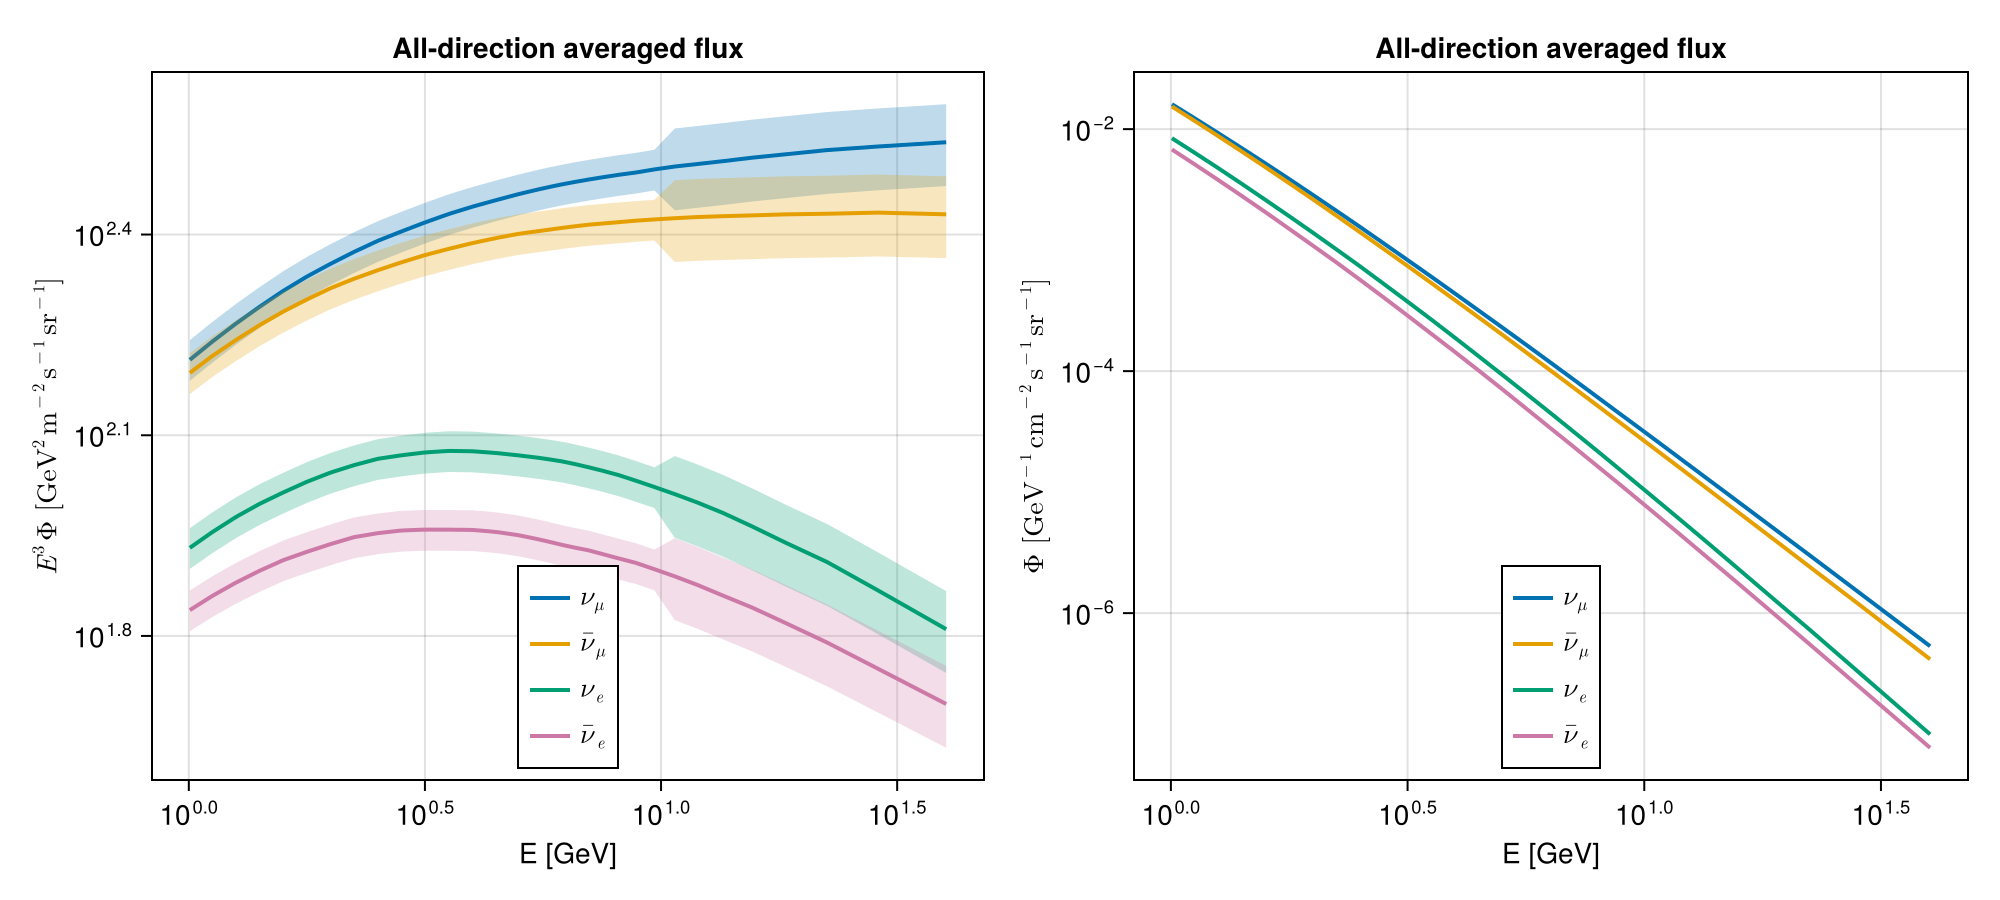

In [11]:
nuflux = produce_neutrino_flux(Dict{String, Any}(
    "bin_centers_arrays"   => (energies, Δcosθs),
    "return_uncertainties" => true
))

flux_νe      = nuflux["Nue_flux"]
flux_νμ      = nuflux["NuMu_flux"]
flux_aνe     = nuflux["AntiNue_flux"]
flux_aνμ     = nuflux["AntiNuMu_flux"]

flux_νe_err  = nuflux["Nue_flux_err"]
flux_νμ_err  = nuflux["NuMu_flux_err"]
flux_aνe_err = nuflux["AntiNue_flux_err"]
flux_aνμ_err = nuflux["AntiNuMu_flux_err"]

E            = nuflux["Energies"]       
cosθ         = nuflux["cosθs"]; 


flux_list     = [flux_νμ,     flux_aνμ,     flux_νe,     flux_aνe]
flux_err_list = [flux_νμ_err, flux_aνμ_err, flux_νe_err, flux_aνe_err]
labels        = [L"\nu_\mu", L"\bar\nu_\mu", L"\nu_e", L"\bar\nu_e"]
colors        = Makie.wong_colors()[1:4]

fig1 = Figure(size = (1000, 450))

ax1 = Axis(fig1[1, 1]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"E^3\,\Phi\ [\mathrm{GeV^{2}\,m^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2))
    Δφ = vec(mean(err,  dims = 2))
    band!(ax1, E, E .^ 3 .* (φ .- Δφ), E .^ 3 .* (φ .+ Δφ); color = (c, 0.25))
    lines!(ax1, E, E .^ 3 .* φ; label = label, linewidth = 2, color = c)
end
axislegend(ax1; position = :cb)

ax2 = Axis(fig1[1, 2]; 
           xscale = log10, yscale = log10,
           xlabel = "E [GeV]",
           ylabel = L"\Phi\ [\mathrm{GeV^{-1}\,cm^{-2}\,s^{-1}\,sr^{-1}}]",
           title  = "All-direction averaged flux")
for (label, flux, err, c) in zip(labels, flux_list, flux_err_list, colors)
    φ  = vec(mean(flux, dims = 2)) ./ 10000.
    lines!(ax2, E, φ; label = label, linewidth = 2, color = c)
end
axislegend(ax2; position = :cb)

fig1


# Calculation of neutrino oscillation probabilities for 

In [12]:
Eνs    = nuflux["Energies"]     
cosθs_tot = nuflux["cosθs"]

println("costhetgrid size: ", size(cosθs_tot))
println("costhetgrid size, first 400 elements: ", size(cosθs_tot[1:400]), ", First element: ", first(cosθs_tot[1:400]), " Last element: ", last(cosθs_tot[1:400]))
println("costhetgrid size, last 400 elements: ", size(cosθs_tot[end-399:end]), ", First element: ", first(cosθs_tot[end-399:end]), " Last element: ", last(cosθs_tot[end-399:end]))


costhetgrid size: (500,)
costhetgrid size, first 400 elements: (400,), First element: -0.999 Last element: -0.201
costhetgrid size, last 400 elements: (400,), First element: -0.799 Last element: -0.001


# END OF THE TEST

In [13]:


θ_tot = ROOT.std.vector["double"]()
for cosθ in cosθs_tot
    θ_tot.push_back(rad2deg(acos(cosθ)))
    println("cosθ: ", cosθ, " → θ: ", rad2deg(acos(cosθ)))
end



ϕ0 = 0.0  # fixed azimuth [degrees]

earth.ResetBlockMaterialCache()  # start from clean PREM state
paths_ref = earth.GetEarthPath(θ_tot, ϕ0)



cosθ: -0.999 → θ: 177.43744126687687
cosθ: -0.997 → θ: 175.56077772515712
cosθ: -0.995 → θ: 174.26803203480227
cosθ: -0.993 → θ: 173.21671109376666
cosθ: -0.991 → θ: 172.30718754844014
cosθ: -0.989 → θ: 171.49385304652293
cosθ: -0.987 → θ: 170.7512952089711
cosθ: -0.985 → θ: 170.0636329278593
cosθ: -0.983 → θ: 169.42015590387751
cosθ: -0.981 → θ: 168.81323611904006
cosθ: -0.979 → θ: 168.23721291450588
cosθ: -0.977 → θ: 167.6877484941811
cosθ: -0.975 → θ: 167.16143185901595
cosθ: -0.973 → θ: 166.65552328596684
cosθ: -0.971 → θ: 166.16778281653646
cosθ: -0.969 → θ: 165.69635127836943
cosθ: -0.967 → θ: 165.2396654185305
cosθ: -0.965 → θ: 164.79639590670698
cosθ: -0.963 → θ: 164.3654010989805
cosθ: -0.961 → θ: 163.94569192572578
cosθ: -0.9590000000000001 → θ: 163.53640479772974
cosθ: -0.9570000000000001 → θ: 163.1367804002112
cosθ: -0.9550000000000001 → θ: 162.74614688264273
cosθ: -0.9530000000000001 → θ: 162.36390637955165
cosθ: -0.9510000000000001 → θ: 161.989524089506
cosθ: -0.949000000

[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPaths] WARNING: after 20 init retries, track not in a BlockVol. Volume: "EarthTopSphere"  IsOutside=0  IsOnBoundary=0
[EarthPa


cosθ: -0.041 → θ: 92.34978560546043
cosθ: -0.039 → θ: 92.23510224379568
cosθ: -0.037000000000000005 → θ: 92.12042784073074
cosθ: -0.035 → θ: 92.00576193490983
cosθ: -0.033 → θ: 91.89110406528417
cosθ: -0.031 → θ: 91.77645377109526
cosθ: -0.029 → θ: 91.66181059185813
cosθ: -0.027000000000000003 → θ: 91.54717406734457
cosθ: -0.025 → θ: 91.43254373756652
cosθ: -0.023 → θ: 91.31791914275931
cosθ: -0.021 → θ: 91.20329982336514
cosθ: -0.019000000000000003 → θ: 91.08868532001638
cosθ: -0.017 → θ: 90.97407517351895
cosθ: -0.015 → θ: 90.85946892483582
cosθ: -0.013 → θ: 90.74486611507035
cosθ: -0.011 → θ: 90.63026628544978
cosθ: -0.009 → θ: 90.5156689773087
cosθ: -0.007 → θ: 90.40107373207253
cosθ: -0.005 → θ: 90.28648009124092
cosθ: -0.003 → θ: 90.1718875963713
cosθ: -0.001 → θ: 90.05729578906238
[Earth::GetEarthPath] Building Earth paths for 500 angles.
[Earth::GetEarthPath] Free cache  paths for 500 angles.
[Earth::GetEarthPath] Finished building paths for 500 angles.


Python: vector<ModularEarth::PropaPath>{ @0x1b890ba0, @0x1b890c10, @0x1b890c80, @0x1b890cf0, @0x1b890d60, @0x1b890dd0, @0x1b890e40, @0x1b890eb0, @0x1b890f20, @0x1b890f90, @0x1b891000, @0x1b891070, @0x1b8910e0, @0x1b891150, @0x1b8911c0, @0x1b891230, @0x1b8912a0, @0x1b891310, @0x1b891380, @0x1b8913f0, @0x1b891460, @0x1b8914d0, @0x1b891540, @0x1b8915b0, @0x1b891620, @0x1b891690, @0x1b891700, @0x1b891770, @0x1b8917e0, @0x1b891850, @0x1b8918c0, @0x1b891930, @0x1b8919a0, @0x1b891a10, @0x1b891a80, @0x1b891af0, @0x1b891b60, @0x1b891bd0, @0x1b891c40, @0x1b891cb0, @0x1b891d20, @0x1b891d90, @0x1b891e00, @0x1b891e70, @0x1b891ee0, @0x1b891f50, @0x1b891fc0, @0x1b892030, @0x1b8920a0, @0x1b892110, @0x1b892180, @0x1b8921f0, @0x1b892260, @0x1b8922d0, @0x1b892340, @0x1b8923b0, @0x1b892420, @0x1b892490, @0x1b892500, @0x1b892570, @0x1b8925e0, @0x1b892650, @0x1b8926c0, @0x1b892730, @0x1b8927a0, @0x1b892810, @0x1b892880, @0x1b8928f0, @0x1b892960, @0x1b8929d0, @0x1b892a40, @0x1b892ab0, @0x1b892b20, @0x1b892b9

extrema((sum(path.baseline) for path = paths)) = (12.741990001825627, 12729.256689999907)
Plotting path 1 of 500
Plotting path 2 of 500
Plotting path 3 of 500
Plotting path 4 of 500
Plotting path 5 of 500
Plotting path 6 of 500
Plotting path 7 of 500
Plotting path 8 of 500
Plotting path 9 of 500
Plotting path 10 of 500


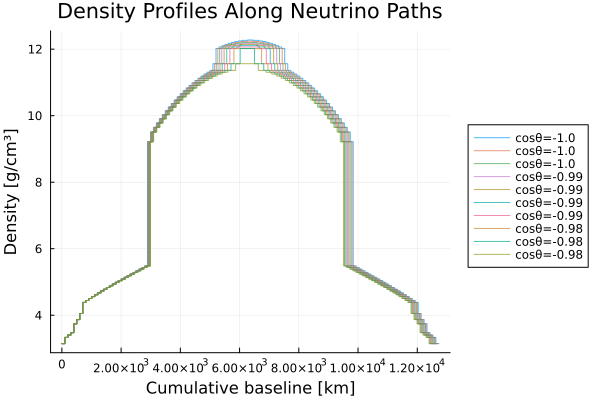

In [14]:


@assert pyconvert(Int, paths_ref.size()) == length(cosθs_tot)

# struct Path
#    density::Vector{Float64}  # effective density seen by oscillations [g/cm³]
#    baseline::Vector{Float64} # segment lengths [km]
# end

# Convert each PropaPath → flexOPT Path.
# PropaPath.ne  = ρ × Ye per segment [g/cm³] (electron density proxy)
# PropaPath.baseline = segment lengths [km]
# Path.density = effective mass density = ne / reference_z_over_a
referenceZOverAForOscillation = 0.5

paths = [
    Path(
        pyconvert(Vector{Float64}, p.ne) ./ referenceZOverAForOscillation,
        pyconvert(Vector{Float64}, p.baseline),
    )
    for p in paths_ref
]

@assert length(paths) == length(cosθs_tot)
@assert all(path -> length(path.density) == length(path.baseline), paths)
@show extrema(sum(path.baseline) for path in paths)  # total path length [km]

function plot_density_profiles(paths; N=10)
    N = min(N, length(paths))

    plt = Plots.plot(
        xlabel = "Cumulative baseline [km]",
        ylabel = "Density [g/cm³]",
        title = "Density Profiles Along Neutrino Paths",
        linewidth = 2,
        legend = :outerright
    )

    for i in 1:N
        println("Plotting path $i of $(length(paths))")
        p = paths[i]

        baseline = p.baseline
        density  = p.density

        @assert length(baseline) == length(density)

        # Cumulative baseline boundaries
        x = vcat(0.0, cumsum(baseline))

        # Build step-like coordinates
        x_step = Float64[]
        y_step = Float64[]

        for j in eachindex(baseline)
            push!(x_step, x[j], x[j+1])
            push!(y_step, density[j], density[j])
        end

        Plots.plot!(
            plt,
            x_step, y_step,
            label = "cosθ=$(round(cosθs_tot[i]; digits=2))",
            alpha = 0.7
        )
    end

    return plt
end
plt = plot_density_profiles(paths; N=10)
display(plt)

In [15]:
paths = [
    Path(
        pyconvert(Vector{Float64}, p.ne) ./ referenceZOverAForOscillation,
        pyconvert(Vector{Float64}, p.baseline),
    )
    for p in paths_ref
]

500-element Vector{Path}:
 Path([3.1469776799999996, 3.33344752, 3.4043888, 3.477708, 3.7431433199999997, 3.87095652, 4.05227292, 4.38429, 4.44383708, 4.50308692  …  4.50308692, 4.44383708, 4.38429, 4.05227292, 3.87095652, 3.7431433199999997, 3.477708, 3.4043888, 3.33344752, 3.1469776799999996], [99.6512238669875, 99.64448405915027, 99.65792644626345, 99.66153049261084, 99.65530644132923, 99.66930193245935, 99.673496244548, 99.67791583223789, 99.67256357213319, 99.68749760616993  …  99.68749760616902, 99.6725635721341, 99.67791583223789, 99.673496244548, 99.66930193246026, 99.65530644132832, 99.66153049261084, 99.65792644626163, 99.64448405915209, 99.6512238668799])
 Path([3.1469776799999996, 3.33344752, 3.4043888, 3.477708, 3.7431433199999997, 3.87095652, 4.05227292, 4.38429, 4.44383708, 4.50308692  …  4.50308692, 4.44383708, 4.38429, 4.05227292, 3.87095652, 3.7431433199999997, 3.477708, 3.4043888, 3.33344752, 3.1469776799999996], [99.85431547973712, 99.85414720877452, 99.874530281831

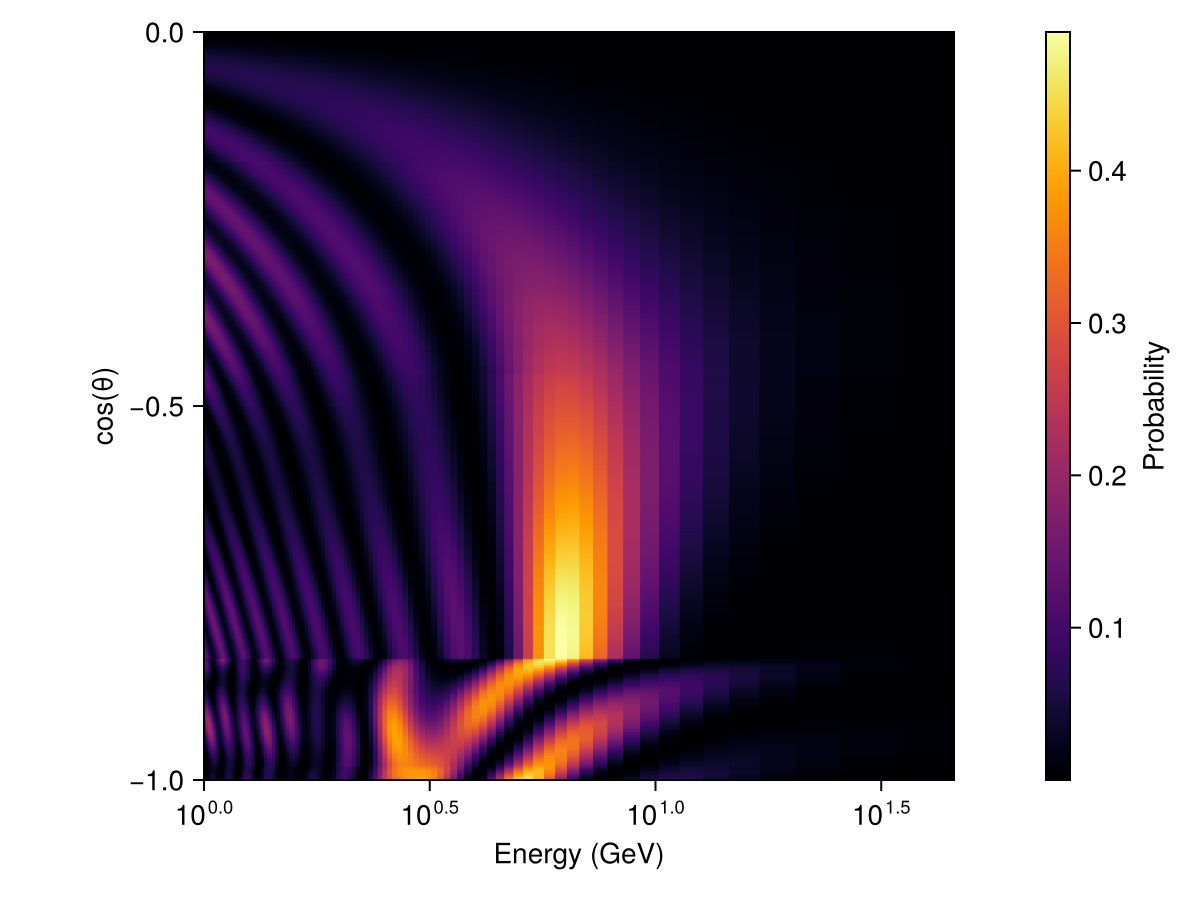

CairoMakie.Screen{IMAGE}


In [16]:

# Oscillation parameters and propagation
osc = set_oscillation_parameters()

probabilities = Pνν(
    osc,
    Eνs,
    paths;
    zoa=referenceZOverAForOscillation,
    roundU_and_H=false
)

antineutrinoProbabilities = Pνν(
    osc,
    Eνs,
    paths;
    zoa=referenceZOverAForOscillation,
    anti=true,
    roundU_and_H=false,
)

@assert size(antineutrinoProbabilities) == size(probabilities)
probs = probabilities[:, :, 1, 2]  # 1 -> 2: electron to muon
matprobs = parent(probs)

fig = Figure()
ax = Axis(
    fig[1, 1],
    aspect = 1,
    xscale = log10,
    xlabel = "Energy (GeV)",
    ylabel = "cos(θ)"
)

hm = Makie.heatmap!(
    ax,
    Eνs,
    cosθs_tot,
    matprobs,
    colormap = :inferno
)

Makie.Colorbar(fig[:, 2], hm, label = "Probability")

display(fig)

##

# 3) Neutrino Interaction Cross Sections \sigma^CC

In [17]:
# Evaluate all CC and NC cross sections on exactly the propagation/flux
# energy grid. Values are (σ/E) × 10⁻⁴² m²/GeV per nucleon.
neutrinoCrossSectionTable = evaluate_neutrino_cross_sections(
    Eνs,
)

@assert neutrinoCrossSectionTable.energies == Eνs
@assert length(neutrinoCrossSectionTable.νe_CC) == numberEnergyBins

cs_νe_CC = neutrinoCrossSectionTable.νe_CC
cs_νμ_CC = neutrinoCrossSectionTable.νμ_CC
cs_ντ_CC = neutrinoCrossSectionTable.ντ_CC
cs_antiνe_CC = neutrinoCrossSectionTable.antiνe_CC
cs_antiνμ_CC = neutrinoCrossSectionTable.antiνμ_CC
cs_antiντ_CC = neutrinoCrossSectionTable.antiντ_CC


100-element Vector{Float64}:
 2.635502044742858e-21
 0.0
 0.0
 0.0
 0.0
 1.2166872758184647e-21
 2.317444782635239e-20
 4.05263693939955e-20
 3.3536997160898904e-20
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.07928386878811224
 0.08675775533903435
 0.09450345857506424
 0.10232562059594183
 0.11039329642549339
 0.11956056283784132
 0.12950738227354
 0.13972767158857957
 0.15138781455214162
 0.16583433323963423
 0.1824776180790089
 0.20449213403475502

In [18]:
# The source path and units travel with the evaluated data.
@show neutrinoCrossSectionTable.source
@show neutrinoCrossSectionTable.units
@show extrema(neutrinoCrossSectionTable.energies)


neutrinoCrossSectionTable.source = "/home/ydenizhernandez/flexOPT/dataInput/neutrinoCrossSections/cross_sections.json"
neutrinoCrossSectionTable.units = Symbol("(σ/E)_1e-42_m2_per_GeV_per_nucleon")
extrema(neutrinoCrossSectionTable.energies) = (1.0049241282283188, 40.16064257028113)


(1.0049241282283188, 40.16064257028113)

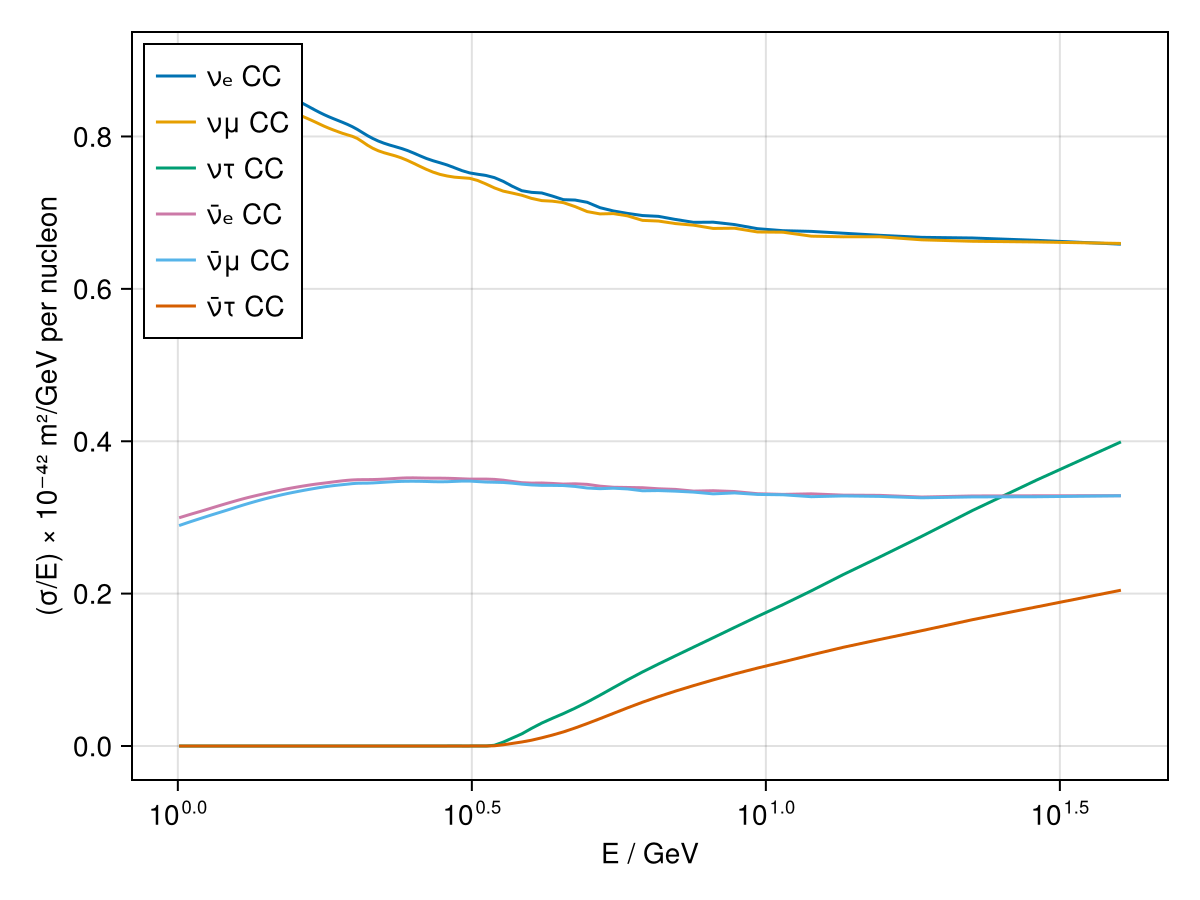

In [19]:
# Makie diagnostic corresponding to the six charged-current curves.
crossSectionPlot = plot_neutrino_cross_sections(
    neutrinoCrossSectionTable;
    channels=:CC,
)
crossSectionPlot.figure


# Interacting events for a perfect detector

In [20]:
# Ideal detector: one calendar year and 1 Mt, before efficiency,
# reconstruction, energy resolution, and angular resolution.
perfectDetector = PerfectDetector(
    mass_kg    = 2*10.0e9,
    livetime_s = 10*365.25 * 24.0 * 60.0 * 60.0,
)
@show perfectDetector

perfectDetector = PerfectDetector(2.0e10, 3.15576e8, 1.67262e-27)


PerfectDetector(2.0e10, 3.15576e8, 1.67262e-27)

In [21]:
# Pack the per-azimuth flux slice into the named tuple that
# interacting_events() expects (energies and cosθgrid must be
# strictly increasing 1-D vectors; νe/νμ/antiνe/antiνμ are (nE, ncosθ)).
neutrinoFluxTable = (
    energies = Eνs,
    cosθgrid = cosθs_tot,
    νe       = flux_νe,
    νμ       = flux_νμ,
    antiνe   = flux_aνe,
    antiνμ   = flux_aνμ,
)

@assert size(neutrinoFluxTable.νe) == (length(Eνs), length(cosθs_tot))
@show size(neutrinoFluxTable.νe)

size(neutrinoFluxTable.νe) = (100, 500)


(100, 500)

In [22]:
# Compute all ν/antiν charged-current event histograms together.
# No transpose, push!, empirical factor 10, or manual E² factor is needed.
perfectDetectorEvents = interacting_events(
    neutrinoFluxTable,
    neutrinoCrossSectionTable,
    probabilities,
    antineutrinoProbabilities;
    detector=perfectDetector,
)

@assert perfectDetectorEvents.energies == neutrinoFluxTable.energies
@assert perfectDetectorEvents.cosθgrid == neutrinoFluxTable.cosθgrid
@assert size(perfectDetectorEvents.combined.νe) == size(flux_νe)
@assert isapprox(sum(perfectDetectorEvents.cosθ_bin_widths),
                 last(cosθs_tot) - first(cosθs_tot))

@show sum(perfectDetectorEvents.combined.νe)
@show sum(perfectDetectorEvents.combined.νμ)
@show sum(perfectDetectorEvents.combined.ντ)
@show sum(perfectDetectorEvents.combined.total)


sum(perfectDetectorEvents.combined.νe) = 2.6157003458348108e6
sum(perfectDetectorEvents.combined.νμ) = 2.9143867096969634e6
sum(perfectDetectorEvents.combined.ντ) = 173356.9761838072
sum(perfectDetectorEvents.combined.total) = 5.703444031715582e6


5.703444031715582e6

In [23]:
function plot_Nint(
    events::PerfectDetectorEventTable;
    flavor::Symbol=:νe,
    component::Symbol=:combined,
    logscale::Bool=true,
)
    component in (:neutrino, :antineutrino, :combined) ||
        throw(ArgumentError(
            "component must be :neutrino, :antineutrino or :combined",
        ))
    selected = getproperty(events, component)
    hasproperty(selected, flavor) ||
        throw(ArgumentError(
            "flavor $flavor is unavailable for component $component",
        ))
    counts = getproperty(selected, flavor)
    plotted = if logscale
        log10.(max.(counts, floatmin(Float64)))
    else
        counts
    end

    figure = Figure()
    axis = Axis(
        figure[1, 1];
        xlabel="log₁₀(E / GeV)",
        ylabel="cosθ",
        title="$(component) $(flavor)",
    )
    heatmap_plot = CairoMakie.heatmap!(
        axis,
        log10.(events.energies),
        events.cosθgrid,
        plotted,
    )
    colorbar = CairoMakie.Colorbar(
        figure[1, 2],
        heatmap_plot;
        label=logscale ? "log₁₀(events/bin)" : "events/bin",
    )
    return (; figure, axis, plot=heatmap_plot, colorbar)
end

plot_Nint (generic function with 1 method)

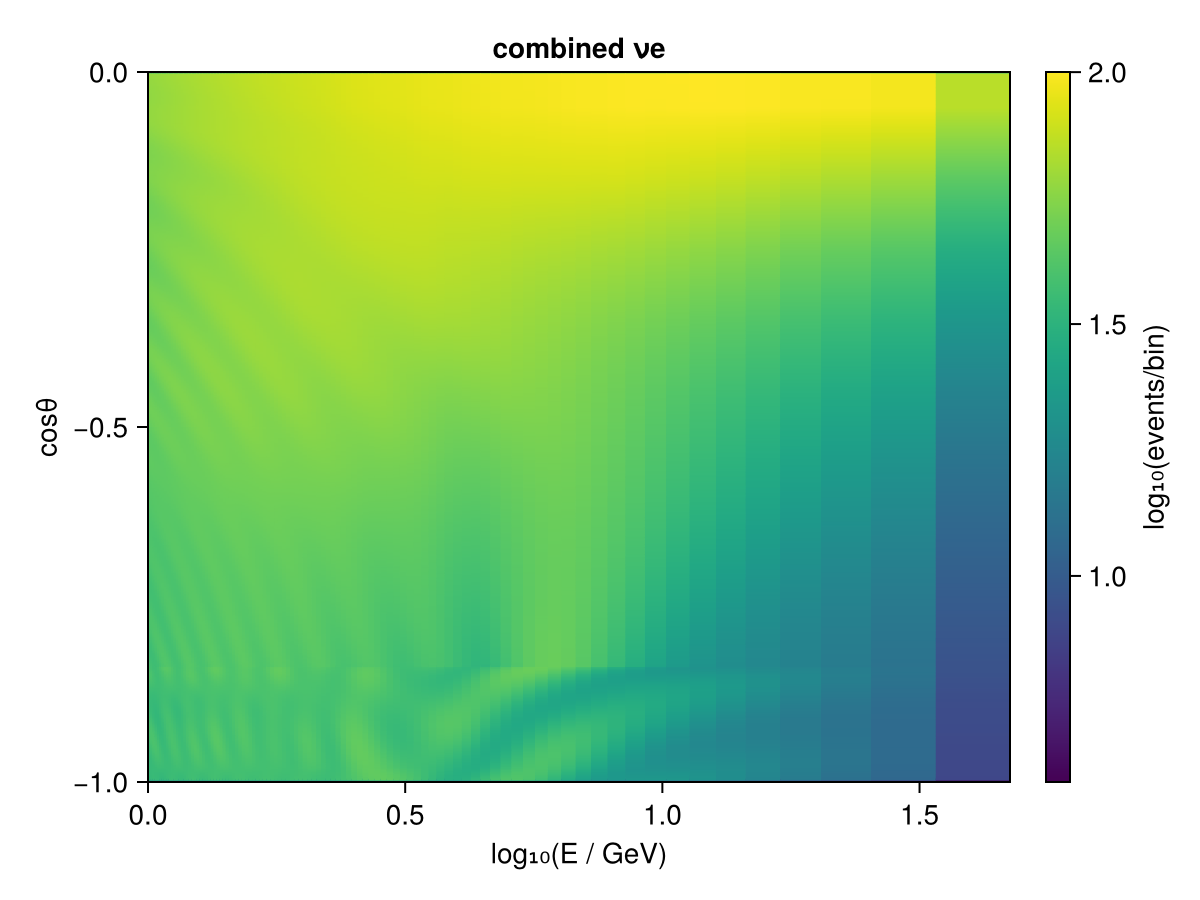

In [24]:
# Combined νₑ + antiνₑ charged-current events per (E, cosθ) bin.
electronEventPlot = plot_Nint(
    perfectDetectorEvents;
    flavor=:νe,
    component=:combined,
)
electronEventPlot.figure


In [25]:
perfectDetectorEvents

(energies = [1.0049241282283188, 1.0149193139145438, 1.0251153254741159, 1.0355182768975872, 1.046134532900931, 1.056970721911003, 1.0680337498664958, 1.0793308148947653, 1.0908694229300753, 1.1026574043444701  …  8.841732979664014, 9.68054211035818, 10.695187165775401, 11.947431302270012, 13.531799729364003, 15.600624024960997, 18.41620626151013, 22.471910112359552, 28.81844380403458, 40.16064257028113], cosθgrid = [-0.999, -0.997, -0.995, -0.993, -0.991, -0.989, -0.987, -0.985, -0.983, -0.981  …  -0.019000000000000003, -0.017, -0.015, -0.013, -0.011, -0.009, -0.007, -0.005, -0.003, -0.001], energy_bin_widths = [0.0099458463330242, 0.010095224086744903, 0.01029909167543508, 0.010509197830149919, 0.01072579971986376, 0.010949167903137047, 0.0111795871734921, 0.011417357467716771, 0.01166279484252164, 0.01191623252547358  …  0.7697436392796693, 0.9235893045599965, 1.1287569238055664, 1.4109793520003429, 1.8144747587748924, 2.4206170616179747, 3.393184597243337, 5.104855828410031, 8.5720

In [26]:
extrema(perfectDetectorEvents.neutrino.νe)

(2.7776606986088033, 72.99309939639694)

In [27]:
# ── Per-flavor, per-particle/antiparticle event counts ───────────────────
# Each array has shape (nE, ncosθ) — events per (energy, angle) bin.

# Neutrinos
νe_events  = perfectDetectorEvents.neutrino.νe   # ν_e CC
νμ_events  = perfectDetectorEvents.neutrino.νμ   # ν_μ CC
ντ_events  = perfectDetectorEvents.neutrino.ντ   # ν_τ CC

# Antineutrinos
antiνe_events = perfectDetectorEvents.antineutrino.νe   # ν̄_e CC
antiνμ_events = perfectDetectorEvents.antineutrino.νμ   # ν̄_μ CC
antiντ_events = perfectDetectorEvents.antineutrino.ντ   # ν̄_τ CC

# ν + ν̄ combined per flavor
comb_νe    = perfectDetectorEvents.combined.νe    # ν_e + ν̄_e
comb_νμ    = perfectDetectorEvents.combined.νμ    # ν_μ + ν̄_μ
comb_ντ    = perfectDetectorEvents.combined.ντ    # ν_τ + ν̄_τ
comb_total = perfectDetectorEvents.combined.total  # all flavors

# Summary: total CC events per component
println("ν_e:   ", round(sum(νe_events);  digits=1))
println("ν_μ:   ", round(sum(νμ_events);  digits=1))
println("ν_τ:   ", round(sum(ντ_events);  digits=1))
println("ν̄_e:  ", round(sum(antiνe_events); digits=1))
println("ν̄_μ:  ", round(sum(antiνμ_events); digits=1))
println("ν̄_τ:  ", round(sum(antiντ_events); digits=1))
println("comb νe:  ", round(sum(comb_νe);    digits=1))
println("comb νμ:  ", round(sum(comb_νμ);    digits=1))
println("comb ντ:  ", round(sum(comb_ντ);    digits=1))
println("TOTAL:    ", round(sum(comb_total);  digits=1))

ν_e:   1.9866356e6
ν_μ:   2.0892686e6
ν_τ:   118287.8
ν̄_e:  629064.8
ν̄_μ:  825118.1
ν̄_τ:  55069.2
comb νe:  2.6157003e6
comb νμ:  2.9143867e6
comb ντ:  173357.0
TOTAL:    5.703444e6


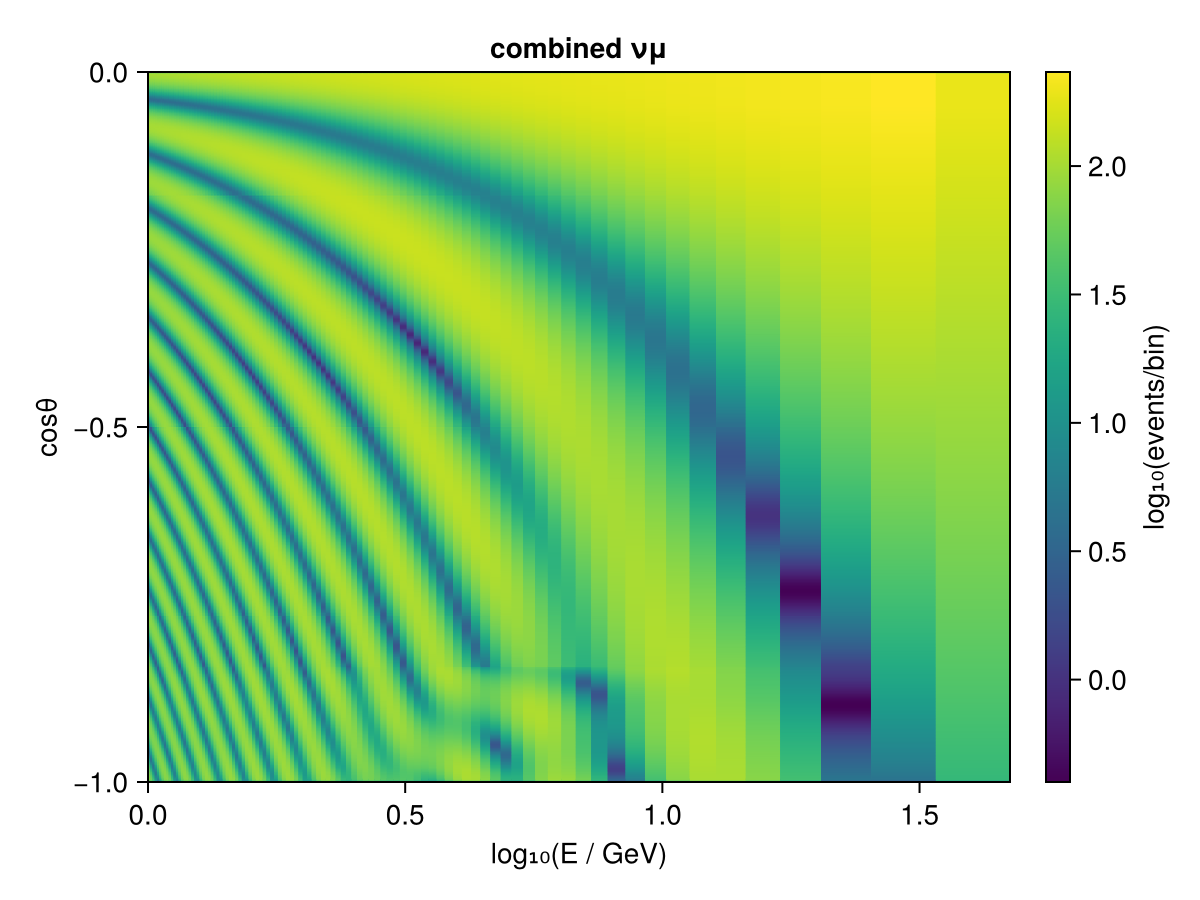

In [28]:
# 1. Total events in the entire sample
sum(perfectDetectorEvents.combined.total)

# 2. Energy spectrum (summed over all angles)
E_spectrum = vec(sum(perfectDetectorEvents.combined.total, dims=2))   # length nE

# 3. Angular distribution (summed over all energies)
cos_spectrum = vec(sum(perfectDetectorEvents.combined.total, dims=1))  # length ncosθ

# 4. νμ appearance fraction at each bin
appearance_fraction = perfectDetectorEvents.combined.νμ ./ perfectDetectorEvents.combined.total

# 5. ν vs ν̄ asymmetry for νe
asymmetry = (perfectDetectorEvents.neutrino.νe .- perfectDetectorEvents.antineutrino.νe) ./
            (perfectDetectorEvents.neutrino.νe .+ perfectDetectorEvents.antineutrino.νe)

# 6. Built-in plot (Makie required)
plot_Nint(perfectDetectorEvents; flavor=:νμ, component=:combined, logscale=true).figure


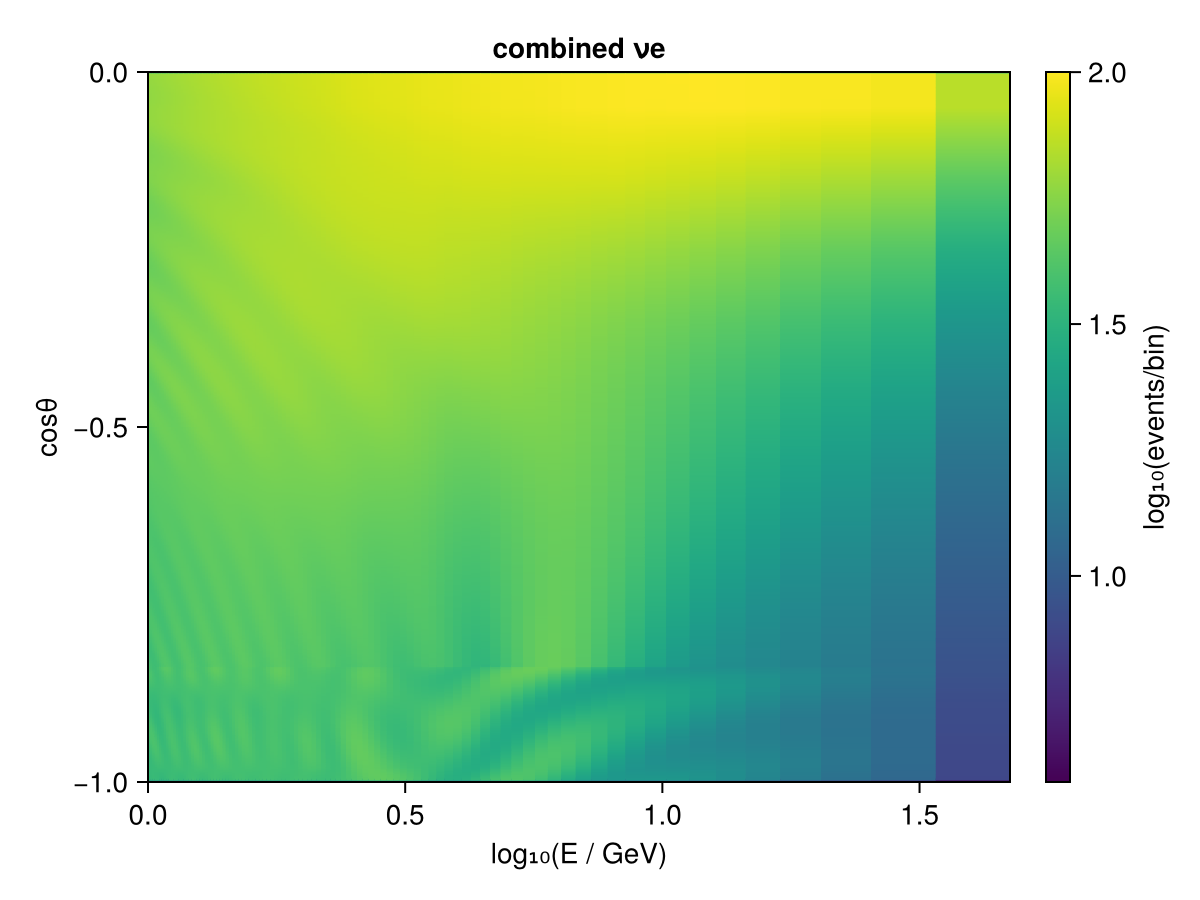

In [29]:
plot_Nint(perfectDetectorEvents; flavor=:νe, component=:combined).figure

# Ingridients for Preliminary Inversion

In [30]:
# forward_prediction computes d_n = g(m_n)

function forward_prediction(
    m_params,
    referenceZOverAForOscillation,
    earth,
    neutrinoFluxTable,
    neutrinoCrossSectionTable,
    detector,
)

    osc         = set_oscillation_parameters()
    Layer_cache = earth.GetBlockMaterialCacheOriginal()
    n_layers    = pyconvert(Int, Layer_cache.size())

    i_global = 0

    for i_layer in 1:n_layers

        n_sublayers = pyconvert(Int, Layer_cache[i_layer-1].size())

        for i_sly in 1:n_sublayers

            i_global += 1
     
            # Read original eYield before any mutation
            current_density = pyconvert(Float64, Layer_cache[i_layer-1][i_sly-1][0].density)
            updatd_eYield  = m_params[i_global]/current_density # n_e / ρ = Y_e
            earth.SetSublayerEYield(i_layer, i_sly, updatd_eYield)

        end # sublayer loop
    end # layer loop
        
        paths_updated = earth.UpdateEarthPath()

        #-----
        paths_modified = [
            Path(
                pyconvert(Vector{Float64}, p.ne) ./ referenceZOverAForOscillation,
                pyconvert(Vector{Float64}, p.baseline),
            )
            for p in paths_updated
        ]
        #------

        prob_m = Pνν(
            osc, neutrinoFluxTable.energies, paths_modified;
            zoa=referenceZOverAForOscillation, roundU_and_H=false,
        )
        antiprob_m = Pνν(
            osc, neutrinoFluxTable.energies, paths_modified;
            zoa=referenceZOverAForOscillation, anti=true, roundU_and_H=false,
        )

        Nint_m = interacting_events(
            neutrinoFluxTable, neutrinoCrossSectionTable,
            prob_m, antiprob_m;
            detector=detector,
        )

            finally
                earth.ResetBlockMaterialCache()
            end

    return (νe_mn    = Nint_m.neutrino.νe,
            νμ_mn     = Nint_m.neutrino.νμ,
            ντ_mn     = Nint_m.neutrino.ντ,
            antivνe_mn = Nint_m.antineutrino.νe,
            antivνμ_mn = Nint_m.antineutrino.νμ,
            antivντ_mn = Nint_m.antineutrino.ντ,
            comb_νe_mn    = Nint_m.combined.νe,
            comb_νμ_mn    = Nint_m.combined.νμ,
            comb_ντ_mn    = Nint_m.combined.ντ,
            comb_total_mn = Nint_m.combined.total )
end

# forward_linerarize_prediction computes d_n = g(m_0) + G (m_n - m_0) <-Frechet derivative linearization

LoadError: ParseError:
[90m# Error @ [0;0m]8;;file:///home/ydenizhernandez/ModularEarth/In[30]#61:13\[90mIn[30]:61:13[0;0m]8;;\

            [48;2;120;70;70m[0;0mfinally
[90m#           └ ── [0;0m[91mExpected `end`[0;0m

In [31]:
# Fréchet derivative of neutrino event counts w.r.t. sublayer electron number density (nₑ).
# Central finite difference: ∂N/∂nₑᵢ ≈ (N(m; nₑᵢ+ε) − N(m; nₑᵢ−ε)) / (2ε)
# All sublayers are held at m_params; only sublayer i is perturbed per column.
#
# Prerequisites (must be done before calling):
#   earth.BuildEarth()
#   earth.SetDetectorLocation(lon, lat, R)
#   earth.GetEarthPath(θ_grid, ϕ0)   ← establishes the angle grid used by UpdateEarthPath(true)

function frechet_derivative(
    m_params,       # nₑ for each sublayer at the expansion point (current iterate m_n)
    dm_params,      # perturbation size per sublayer (in nₑ units)
    referenceZOverAForOscillation,
    earth,
    neutrinoFluxTable,
    neutrinoCrossSectionTable,
    detector,
)
    nE    = length(neutrinoFluxTable.energies)
    ncosθ = length(neutrinoFluxTable.cosθgrid)
    Nm    = length(dm_params)

    osc      = set_oscillation_parameters()
    ne_cache = earth.GetBlockElectronNdensityCacheOriginal()  # read-only: layer/sublayer structure only
    n_layers = pyconvert(Int, ne_cache.size())

    # ── Initialize mutable ne cache to expansion point m_params ──────────────
    # Every sublayer must be at m_params before we start perturbing one at a time.
    # Uses ne_cache (original) only for the layer/sublayer structure counts.
    earth.ResetElectronNdensityCache()
    i_g = 0
    for i_layer in 1:n_layers
        n_sly_init = pyconvert(Int, ne_cache[i_layer-1].size())
        for i_sly in 1:n_sly_init
            i_g += 1
            earth.OverrideSublayerNe(i_layer, i_sly, m_params[i_g])
        end
    end
    @assert i_g == Nm "m_params length $(Nm) does not match sublayer count $(i_g)"

    # Pre-allocate one (nE × ncosθ × Nm) kernel per flavor/component
    νe_events_frechet      = Array{Float64}(undef, nE, ncosθ, Nm)
    νμ_events_frechet      = Array{Float64}(undef, nE, ncosθ, Nm)
    ντ_events_frechet      = Array{Float64}(undef, nE, ncosθ, Nm)
    antiνe_events_frechet  = Array{Float64}(undef, nE, ncosθ, Nm)
    antiνμ_events_frechet  = Array{Float64}(undef, nE, ncosθ, Nm)
    antiντ_events_frechet  = Array{Float64}(undef, nE, ncosθ, Nm)
    comb_νe_frechet        = Array{Float64}(undef, nE, ncosθ, Nm)
    comb_νμ_frechet        = Array{Float64}(undef, nE, ncosθ, Nm)
    comb_ντ_frechet        = Array{Float64}(undef, nE, ncosθ, Nm)
    comb_total_frechet     = Array{Float64}(undef, nE, ncosθ, Nm)

    i_global = 0

    for i_layer in 1:n_layers

        n_sublayers = pyconvert(Int, ne_cache[i_layer-1].size())

        for i_sly in 1:n_sublayers

            i_global += 1

            ε           = dm_params[i_global]

            current_ne  = m_params[i_global]  # base ne for this sublayer at expansion point
            @assert abs(current_ne - pyconvert(Float64, earth.GetBlockElectronNdensityCache()[i_layer-1][i_sly-1][0])) < 1e-6 "m_params[$i_global] = $(current_ne) is inconsistent with the current cache value"
            forward_ne  = current_ne + ε
            backward_ne = current_ne - ε

            local Nintνe_fwd, Nintνμ_fwd, Nintντ_fwd
            local Nint_antiνe_fwd, Nint_antiνμ_fwd, Nint_antiντ_fwd
            local Nint_comb_νe_fwd, Nint_comb_νμ_fwd, Nint_comb_ντ_fwd, Nint_comb_total_fwd

            try
                for (ne, is_forward) in ((forward_ne, true), (backward_ne, false))

                    earth.OverrideSublayerNe(i_layer, i_sly, ne)
                    paths_updated = earth.UpdateEarthPath(true)

                    paths_modified = [
                        Path(
                            pyconvert(Vector{Float64}, p.ne) ./ referenceZOverAForOscillation,
                            pyconvert(Vector{Float64}, p.baseline),
                        )
                        for p in paths_updated
                    ]

                    prob_mod = Pνν(
                        osc, neutrinoFluxTable.energies, paths_modified;
                        zoa=referenceZOverAForOscillation, roundU_and_H=false,
                    )
                    antiprob_mod = Pνν(
                        osc, neutrinoFluxTable.energies, paths_modified;
                        zoa=referenceZOverAForOscillation, anti=true, roundU_and_H=false,
                    )

                    Nint = interacting_events(
                        neutrinoFluxTable, neutrinoCrossSectionTable,
                        prob_mod, antiprob_mod;
                        detector=detector,
                    )

                    if is_forward
                        Nintνe_fwd          = Nint.neutrino.νe
                        Nintνμ_fwd          = Nint.neutrino.νμ
                        Nintντ_fwd          = Nint.neutrino.ντ
                        Nint_antiνe_fwd     = Nint.antineutrino.νe
                        Nint_antiνμ_fwd     = Nint.antineutrino.νμ
                        Nint_antiντ_fwd     = Nint.antineutrino.ντ
                        Nint_comb_νe_fwd    = Nint.combined.νe
                        Nint_comb_νμ_fwd    = Nint.combined.νμ
                        Nint_comb_ντ_fwd    = Nint.combined.ντ
                        Nint_comb_total_fwd = Nint.combined.total
                    else
                        # Central finite difference: (N(m; nₑᵢ+ε) − N(m; nₑᵢ−ε)) / (2ε)
                        νe_events_frechet[:, :, i_global]     .= (Nintνe_fwd          .- Nint.neutrino.νe)      ./ (2ε)
                        νμ_events_frechet[:, :, i_global]     .= (Nintνμ_fwd          .- Nint.neutrino.νμ)      ./ (2ε)
                        ντ_events_frechet[:, :, i_global]     .= (Nintντ_fwd          .- Nint.neutrino.ντ)      ./ (2ε)
                        antiνe_events_frechet[:, :, i_global] .= (Nint_antiνe_fwd     .- Nint.antineutrino.νe)  ./ (2ε)
                        antiνμ_events_frechet[:, :, i_global] .= (Nint_antiνμ_fwd     .- Nint.antineutrino.νμ)  ./ (2ε)
                        antiντ_events_frechet[:, :, i_global] .= (Nint_antiντ_fwd     .- Nint.antineutrino.ντ)  ./ (2ε)
                        comb_νe_frechet[:, :, i_global]       .= (Nint_comb_νe_fwd    .- Nint.combined.νe)      ./ (2ε)
                        comb_νμ_frechet[:, :, i_global]       .= (Nint_comb_νμ_fwd    .- Nint.combined.νμ)      ./ (2ε)
                        comb_ντ_frechet[:, :, i_global]       .= (Nint_comb_ντ_fwd    .- Nint.combined.ντ)      ./ (2ε)
                        comb_total_frechet[:, :, i_global]    .= (Nint_comb_total_fwd .- Nint.combined.total)   ./ (2ε)
                    end
                end
            finally
                # Restore only this sublayer to m_params — all other sublayers remain at m_params
                earth.OverrideSublayerNe(i_layer, i_sly, current_ne)
            end

        end # sublayer loop
    end # layer loop

    # Leave earth in a clean state for the caller
    earth.ResetElectronNdensityCache()

    return νe_events_frechet, νμ_events_frechet, ντ_events_frechet,
           antiνe_events_frechet, antiνμ_events_frechet, antiντ_events_frechet,
           comb_νe_frechet, comb_νμ_frechet, comb_ντ_frechet, comb_total_frechet
end


frechet_derivative (generic function with 1 method)

In [32]:
# Jacobian function: computes Frechet derivatives at m_params and assembles G (Nd x Nm)
# d_obs ordering: (comb_numu_flat..., comb_nue_flat...)  — must match d_obs construction
function Jacobian(
    m_params,
    dm_frac,
    referenceZOverAForOscillation,
    earth,
    neutrinoFluxTable,
    neutrinoCrossSectionTable,
    detector,
)
    Nm   = length(m_params)
    nE   = length(neutrinoFluxTable.energies)
    ncosθ = length(neutrinoFluxTable.cosθgrid)
    Nd   = 2 * nE * ncosθ   # νμ bins + νe bins

    # Perturbation vector in ne units
    dm_params = dm_frac .* m_params

    # Frechet derivatives
    _, _, _, _, _, _,
    comb_νe_fd, comb_νμ_fd, _, _ =
        frechet_derivative(
            m_params,
            dm_params,
            referenceZOverAForOscillation,
            earth,
            neutrinoFluxTable,
            neutrinoCrossSectionTable,
            detector,
        )

    # Assemble G: column i = partial d / partial m_i
    # Row ordering matches d_obs = vcat(vec(comb_νμ_obs), vec(comb_νe_obs))
    G = Matrix{Float64}(undef, Nd, Nm)
    for i in 1:Nm
        G[:, i] = vcat(vec(comb_νμ_fd[:, :, i]), vec(comb_νe_fd[:, :, i]))
    end

    return G
end


Jacobian (generic function with 1 method)

In [33]:
# forward_prediction computes d_n = g(m_n)

function forward_prediction(
    m_params,
    referenceZOverAForOscillation,
    earth,
    neutrinoFluxTable,
    neutrinoCrossSectionTable,
    detector,
)

    osc         = set_oscillation_parameters()
    Layer_cache = earth.GetBlockMaterialCacheOriginal()
    n_layers    = pyconvert(Int, Layer_cache.size())

    i_global = 0

    for i_layer in 1:n_layers

        n_sublayers = pyconvert(Int, Layer_cache[i_layer-1].size())

        for i_sly in 1:n_sublayers

            i_global += 1
     
            # Read original eYield before any mutation
            current_density = pyconvert(Float64, Layer_cache[i_layer-1][i_sly-1][0].density)
            updatd_eYield  = m_params[i_global]/current_density # n_e / ρ = Y_e
            earth.SetSublayerEYield(i_layer, i_sly, updatd_eYield)

        end # sublayer loop
    end # layer loop
        
        paths_updated = earth.UpdateEarthPath()

        #-----
        paths_modified = [
            Path(
                pyconvert(Vector{Float64}, p.ne) ./ referenceZOverAForOscillation,
                pyconvert(Vector{Float64}, p.baseline),
            )
            for p in paths_updated
        ]
        #------

        prob_m = Pνν(
            osc, neutrinoFluxTable.energies, paths_modified;
            zoa=referenceZOverAForOscillation, roundU_and_H=false,
        )
        antiprob_m = Pνν(
            osc, neutrinoFluxTable.energies, paths_modified;
            zoa=referenceZOverAForOscillation, anti=true, roundU_and_H=false,
        )

        Nint_m = interacting_events(
            neutrinoFluxTable, neutrinoCrossSectionTable,
            prob_m, antiprob_m;
            detector=detector,
        )

            finally
                earth.ResetBlockMaterialCache()
            end

    return (νe_mn    = Nint_m.neutrino.νe,
            νμ_mn     = Nint_m.neutrino.νμ,
            ντ_mn     = Nint_m.neutrino.ντ,
            antivνe_mn = Nint_m.antineutrino.νe,
            antivνμ_mn = Nint_m.antineutrino.νμ,
            antivντ_mn = Nint_m.antineutrino.ντ,
            comb_νe_mn    = Nint_m.combined.νe,
            comb_νμ_mn    = Nint_m.combined.νμ,
            comb_ντ_mn    = Nint_m.combined.ντ,
            comb_total_mn = Nint_m.combined.total )
end

# forward_linerarize_prediction computes d_n = g(m_0) + G (m_n - m_0) <-Frechet derivative linearization

LoadError: ParseError:
[90m# Error @ [0;0m]8;;file:///home/ydenizhernandez/ModularEarth/In[33]#61:13\[90mIn[33]:61:13[0;0m]8;;\

            [48;2;120;70;70m[0;0mfinally
[90m#           └ ── [0;0m[91mExpected `end`[0;0m

In [34]:
function Set_Covariance_Params(σ_M::Vector{Float64})
    # σ_M[i] = prior uncertainty on sublayer i ne  (length Nm)
    C_M   = Diagonal(σ_M .^ 2)
    Inv_M = Diagonal(1.0 ./ σ_M .^ 2)
    return C_M, Inv_M
end

function Set_Covariance_Obs(σ_D::Vector{Float64})
    # σ_D[i] = uncertainty on observation bin i  (d_obs must be a flat 1D vector, length Nd)
    C_D   = Diagonal(σ_D .^ 2)
    Inv_D = Diagonal(1.0 ./ σ_D .^ 2)
    return C_D, Inv_D
end


Set_Covariance_Obs (generic function with 1 method)

In [35]:
function Set_Covariance_Params(σ_M::Vector{Float64})
    # σ_M[i] = prior uncertainty on sublayer i ne  (length Nm)
    C_M   = Diagonal(σ_M .^ 2)
    Inv_M = Diagonal(1.0 ./ σ_M .^ 2)
    return C_M, Inv_M
end

function Set_Covariance_Data(σ_D::Vector{Float64})
    # σ_D[i] = uncertainty on observation bin i  (d_obs must be a flat 1D vector, length Nd)
    C_D   = Diagonal(σ_D .^ 2)
    Inv_D = Diagonal(1.0 ./ σ_D .^ 2)
    return C_D, Inv_D
end


Set_Covariance_Data (generic function with 1 method)

# Preliminar Inversion

Minimization algorithm will be steepest descend
$m_{n+1} = (m_n) − μ_n * ( (C_M)*(G^{t}_n)*(C^{-1}_D)(d_n-d_{obs}) +  (m_n − m_{prior}) )$

$d_n = (N_{\nu_{\mu}}, N_{\nu_{\mu}})^T$

$μ_n = 0.1,0.5$

In [ ]:
# ── dm_params: 1% anomaly (εᵢ = 0.01 × mᵢ) for every sublayer electron yield ──
Layer_cache = earth.GetBlockMaterialCacheOriginal()
ne_cache_out = earth.GetBlockElectronNdensityCacheOriginal()  # read-only: layer/sublayer structure only

# std::vector<std::vector<std::vector<BlockMatInfo>>> — 0-based C++ indexing
n_layers = pyconvert(Int, Layer_cache.size())
Nm       = sum(pyconvert(Int, Layer_cache[i].size()) for i in 0:n_layers-1)
println("Total model parameters Nm = $Nm")

dm_params = Vector{Float64}(undef, Nm)
m_ref  = Vector{Float64}(undef, Nm)

i_g = 0
for i_layer in 0:n_layers-1
    sublayers   = Layer_cache[i_layer]
    n_sublayers = pyconvert(Int, sublayers.size())
    for i_sly in 0:n_sublayers-1
        i_g += 1
        # BlockMatInfo.eYield from block 0 (uniform material within a sublayer)
        eYield_i   = pyconvert(Float64, sublayers[i_sly][0].eYield)
        density_i  = pyconvert(Float64, sublayers[i_sly][0].density)
        ne_i       = density_i * eYield_i
        ne_from_cache = pyconvert(Float64, ne_cache_out[i_layer][i_sly][0])
        @assert abs(ne_i - ne_from_cache) < 1e-6 "Mismatch between computed ne ($ne_i) and cache ne ($ne_from_cache) for layer $i_layer, sublayer $i_sly"
        m_ref[i_g]  = ne_from_cache
        dm_params[i_g] = 0.01 * ne_from_cache # <---- variation in terms of eyield
        #dm_params[i_g] = 1
    end
end


println("dm_params stats: min=$(minimum(dm_params)), max=$(maximum(dm_params))")
println("dm_params stats: =$((2*dm_params[59]))")
println("dm_params stats: =$((m_ref[59] ))")


Total model parameters Nm = 64
dm_params stats: min=0.015734888399999997, max=0.0614436562
dm_params stats: =0.038709565200000004
dm_params stats: =1.93547826


In [42]:
m_params = copy(m_ref)

νe_events_frechet, νμ_events_frechet, ντ_events_frechet,
           antiνe_events_frechet, antiνμ_events_frechet, antiντ_events_frechet,
           comb_νe_frechet, comb_νμ_frechet, comb_ντ_frechet, comb_total_frechet =  frechet_derivative(
    m_params,       # nₑ for each sublayer at the expansion point (current iterate m_n)
    dm_params,      # perturbation size per sublayer (in nₑ units)
    referenceZOverAForOscillation,
    earth,
    neutrinoFluxTable,
    neutrinoCrossSectionTable,
    detector,
)

LoadError: UndefVarError: `detector` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [ ]:
# ── Heatmap: (m₁₄/100) × ∂N_νμ/∂m₁₄ as a function of (E, cosθ) ─────────────
i_param = 59   # 1-based index → layer #59
m_i    = m_ref[i_param]

# Sensitivity: absolute change in events per 1% perturbation of m_59
sensitivity = (m_i / 100.0) .* comb_νμ_frechet[:, :, i_param]   # (nE, ncosθ)

fd_max = maximum(abs.(sensitivity))
println("Sensitivity range: min=$(minimum(sensitivity)), max=$(maximum(sensitivity)))")


e_ticks = [1, 2, 4, 6, 8, 10, 20, 30]
cth_ticks = [0.0, -0.2, -0.4, -0.6, -0.8, -1.0]

fig = Figure()
ax  = Axis(
    fig[1, 1];
    xlabel = "E (GeV)",
    ylabel = "cos θ",
    title  = "Fréchet derivative  m_59  —  combined νμ",
    xscale = log10,
    xticks = (e_ticks, string.(e_ticks)),
    yticks = (cth_ticks, string.(cth_ticks)),
)
hm  = CairoMakie.heatmap!(
    ax,
    neutrinoFluxTable.energies,
    neutrinoFluxTable.cosθgrid,
    sensitivity;
    colorrange = (-fd_max, fd_max),
)
CairoMakie.Colorbar(fig[1, 2], hm; label = "(m_59/100) × ∂N_νμ/∂m_59  [events/bin]")
fig


LoadError: UndefVarError: `comb_νμ_fd` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [4]:
# Stepest decens algorith 

In [ ]:
#Steppest descend algorithm to update model parameters m_n based on observed data d_obs and forward prediction d_n
c_prior = ne_avg  #  avarage Earth electron number density for model parameters
m_prior =  c_prior*vec(1.0 for i in 1:length(m_ref))  #  constant vector
m_0 = m_prior  # initial guess for model parameters
sigma_D = ones(length(m_0))
C_M, Inv_M = Set_Covariance_Obs(sigma_D)

d_obs = vcat(vec(comb_νμ_obs), vec(comb_νe_obs))  #  observed data vector (combined flatten νμ and νe -like events)
sigma_D = ones(length(d_obs))  # 10% uncertainty on observed data
C_D, Inv_D = Set_Covariance_Data(sigma_D)

μ_n = 0.1 # step size for iterative update of m_n

iter = 0 

residuals = Float64[]

while ( norm(Δd_n) > 1e-6)

    if(iter == 0)
        m_n = m_0
    else
        m_n = m_n1
    end
    
    # Compute forward prediction at current model parameters
    d_forward = forward_prediction(
        m_n,
        referenceZOverAForOscillation,
        earth,
        neutrinoFluxTable,
        neutrinoCrossSectionTable,
        perfectDetector,
    )
    
    # Flatten the predicted data for comparison with observed data
    d_n = vcat(vec(d_forward.comb_νμ_mn), vec(d_forward.comb_νe_mn))
    
    
    # Compute the Jacobian matrix at current model parameters
    G_n = Jacobian(
        m_n,
        0.01,  # small perturbation for finite difference
        referenceZOverAForOscillation,
        earth,
        neutrinoFluxTable,
        neutrinoCrossSectionTable,
        perfectDetector,
    )

        # Compute the residual between observed and predicted data
    Δd_n = d_n - d_obs 

    # Compute the residual between observed and predicted data
    Δm_n = m_n - m_prior

    Gn_adj =C_M .*(G_n').*Inv_D  # Transpose of the Jacobian for gradient computation
    
    # Update model parameters using a simple gradient descent step
    m_n1 = m_n - μ_n * (Gn_adj * Δd_n + Δm_n)

    iter += 1

    residuals = push!(residuals, norm(Δd_n)) #  Store the norm of the residual for convergence monitoring

    # Check for convergence (e.g., if the norm of the residual is below a threshold)
    if norm(Δd_n) < 1e-6
        break
    end
end



C_D = Diag(poisson variance)

m_prior = Array(n_e, tot_model_sly)

C_M = Diag(constant for for constant Earth)



Problem
earth.GetEarthPath(θ_tot, ϕ0) crashes or infinite-loops when θ_tot has ≥600 elements. The same angles split into two calls of ≤500 each always works. The crash is count-driven, not angle-driven — near-horizontal angles alone are fine.

Fixes tried (none confirmed working)
geoManager->CdTop() before every InitTrack — to reset ROOT navigator state
step <= ZEPS break guard — to close an unhandled near-zero step case
Two-layer angle clamping — to prevent angles landing on tile boundaries
Removed per-step and per-angle debug std::cout — to stop flooding Jupyter's output buffer
Best remaining suspects
Boundary stall continue loop — when 20 nudges fail mid-track, the code does continue, re-entering the while loop with the same zero step, potentially forever. A stall counter (break after N consecutive stalls) was designed but not yet applied.
ROOT safety cache not reset by CdTop() — fSafety persists; a more aggressive reset may be needed.
Nth = 180/dth truncation in Sublayer.C:103 — leaves a geometry gap near 180° that can cause BlockMaterialCache[−1 as size_t] out-of-bounds access when a ray passes through it

Moving down the rows = you are stepping through energy bins while holding cosine angle fixed.
Moving across the columns = you are stepping through cosine angle bins while holding energy fixed.
Bottom line: comb_νe[i, j] gives the number of electron neutrino events in energy bin i and cosine-angle bin j. Iterating over i (rows) scans energies; iterating over j (columns) scans directions.

comb_νe[i, j]
         │   └── j = 1..75 → cosθ from −1 (vertical/upgoing) to 0 (horizontal)
         │                    left-to-right across a row
         └────── i = 1..100 → energy from ~1 GeV to ~50 GeV
                              top-to-bottom down a column
Moving down a column (incrementing i, fixed j) = scanning energies at a fixed direction.
Moving across a row (incrementing j, fixed i) = scanning directions at a fixed energy.

Standard Julia Matrix Convention
In Julia, M[i, j] follows standard math matrix notation:

i = row index → increases top to bottom (row 1 is the topmost row -Lowes energy)
j = column index → increases left to right (column 1 is the leftmost column - Longest path, most negative cosine)
So yes: i labels rows from the topmost downward, and j labels elements within that row from left to right.